# **Day 43: Object Oriented Programming (Part 3) - Class Variables, classmethod and staticmethod**

## **Instance Variables vs Class Variables**
- **Instance variable:** Belongs to **one object**. Each object has its own copy. It is made using `self.name = ...` inside `__init__`.
- **Class variable:** Belongs to the **class** and is **shared by all objects**. It is written directly inside the class, outside all methods.

**Example:** Every Kolkata Metro card has its own owner and balance (instance variables), but all cards belong to the same city (class variable).

In [1]:
class MetroCard:
    city = "Kolkata"           # Class variable (shared by all)
    cards_issued = 0           # Class variable (a counter)

    def __init__(self, owner, balance=100):
        self.owner = owner     # Instance variable
        self.balance = balance # Instance variable
        MetroCard.cards_issued += 1

c1 = MetroCard("Ria")
c2 = MetroCard("Sam")

print(c1.city, c2.city, MetroCard.city)
print("Cards issued:", MetroCard.cards_issued)

Kolkata Kolkata Kolkata
Cards issued: 2


## **A Common Mistake: A Shared List**
If we keep a **list** as a class variable, **all objects share the same list**. This is usually not what we want.

In [2]:
class Pandal:
    visitors = []              # Shared by ALL pandals (a mistake)

    def __init__(self, name):
        self.name = name

    def visit(self, who):
        self.visitors.append(who)

a = Pandal("Bagbazar")
b = Pandal("Ekdalia")
a.visit("Rahul")
print(b.visitors)              # Rahul appears in Ekdalia too!

['Rahul']


**The fix:** Create the list inside `__init__` with `self.visitors = []`, so each pandal gets its own list.

## **Three Types of Methods**
| Type | First parameter | Can use | Used for |
|---|---|---|---|
| **Instance method** | `self` (the object) | Object data and class data | Most normal work |
| **Class method** (`@classmethod`) | `cls` (the class) | Class data | Making objects in other ways |
| **Static method** (`@staticmethod`) | nothing | Only its inputs | Helper functions related to the class |

## **@classmethod: Another Way to Create Objects**
A class method is often used as an **alternative constructor**: a different way to make an object, for example from a line of text.

In [3]:
class Person:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    @classmethod
    def from_csv_line(cls, line):
        name, age = line.split(",")
        return cls(name.strip(), int(age))      # cls means Person here

    def __repr__(self):
        return f"Person({self.name!r}, {self.age})"

print(Person.from_csv_line("Arijit, 37"))

Person('Arijit', 37)


## **@staticmethod: A Helper Function Inside the Class**
A static method does not need the object or the class. It is kept inside the class only because it is **related** to it.

In [4]:
class Temperature:
    @staticmethod
    def c_to_f(c):
        return c * 9 / 5 + 32

    @staticmethod
    def is_heatwave(c):
        return c >= 40

print(Temperature.c_to_f(42), Temperature.is_heatwave(42))

107.6 True


## **Example from GIS: A Coordinate Class with All Three Method Types**
- A **class variable** stores the name of the coordinate system (WGS84, the system used by GPS).
- A **class method** makes a Coordinate from **DMS** text.
- A **static method** converts DMS numbers to decimal degrees.

In [5]:
class Coordinate:
    crs = "EPSG:4326 (WGS84)"          # Class variable: same for all coordinates
    count = 0

    def __init__(self, lat, lon):
        self.lat = lat
        self.lon = lon
        Coordinate.count += 1

    @staticmethod
    def dms_to_dd(d, m, s):
        return d + m / 60 + s / 3600

    @classmethod
    def from_dms(cls, lat_dms, lon_dms):
        """Create a Coordinate from two (degree, minute, second) tuples."""
        lat = cls.dms_to_dd(*lat_dms)
        lon = cls.dms_to_dd(*lon_dms)
        return cls(round(lat, 5), round(lon, 5))

    def __repr__(self):
        return f"Coordinate({self.lat}, {self.lon}) in {self.crs}"

c1 = Coordinate(22.5726, 88.3639)                      # Normal way
c2 = Coordinate.from_dms((27, 2, 28), (88, 15, 59))     # From DMS (Darjeeling)

print(c1)
print(c2)
print("Coordinates created:", Coordinate.count)

Coordinate(22.5726, 88.3639) in EPSG:4326 (WGS84)
Coordinate(27.04111, 88.26639) in EPSG:4326 (WGS84)
Coordinates created: 2


**EPSG:4326** is the code number of the **WGS84** coordinate system. It is the latitude-longitude system used by GPS and Google Maps. Every coordinate system has an EPSG code, and GIS software uses these codes to understand the data.

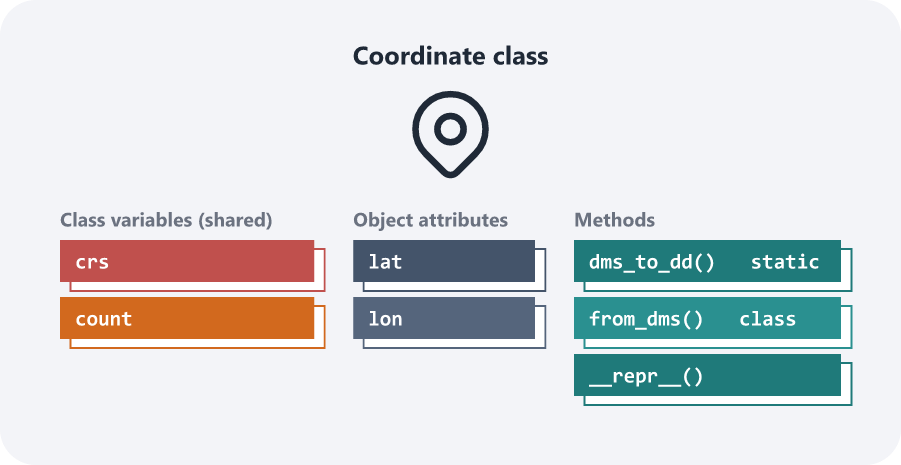

## **Practice Problem: Automatic Ticket Numbers**

In [6]:
class Ticket:
    next_id = 1001             # Class variable

    def __init__(self, src, dst):
        self.id = Ticket.next_id
        Ticket.next_id += 1
        self.src, self.dst = src, dst

    def __repr__(self):
        return f"<Ticket {self.id}: {self.src} -> {self.dst}>"

print([Ticket("Howrah", "Digha"), Ticket("Sealdah", "Lalgola"), Ticket("Howrah", "Puri")])

[<Ticket 1001: Howrah -> Digha>, <Ticket 1002: Sealdah -> Lalgola>, <Ticket 1003: Howrah -> Puri>]


In [7]:
# Quick question
# Guess the output of this code cell
# class C:
#     n = 0
#     def __init__(self):
#         C.n += 1
# C(); C(); C()
# print(C.n)